# Exercise 1 - MLP classifier on CIFAR-10


This exercise investigates the performance of a Multi-Layer Perceptron (MLP) for image classification using the CIFAR-10 dataset. A three-layer MLP is implemented and trained to classify images into ten categories. The model's learning behaviour, classification performance and generalisation ability are evaluated.

Experimental Setup
- Model - MLP with three trainable fully connected layers (512, 256, and 10 neurons).
- Dataset - CIFAR-10, with 45,000 training, 5,000 validation and 10,000 test images.
- Training - 30 epochs, Adam optimiser, learning rate of 0.001, batch size of 128.
- Preprocessing - Tensor conversion and channel-wise normalisation.
- Evaluation - Training, validation and test accuracy and loss, generalisation gap, loss and accuracy curves, and confusion matrix.

In [1]:
import torch
import torchvision
import platform


print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("Using CPU")
    device = torch.device("cpu")

print("\nSelected device:", device)


Python version: 3.13.16
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130

GPU Available: True
GPU Name: Tesla T4

Selected device: cuda


### 1. Downloading and inspecting the dataset



In [2]:
import torch
import torchvision
import torchvision.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Defining dataset location
data_dir = "./data"

# CIFAR-10 class names (label 0-9, in the dataset's order)
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Downloading the original training partition
train_dataset = datasets.CIFAR10(
    root=data_dir,
    train=True,
    download=True
)

# Displaying dataset information

print("Number of training images:", len(train_dataset))
print("Number of classes:", len(class_names))
print("Image shape:", train_dataset.data.shape)
print("Image data type:", train_dataset.data.dtype)

print("\nClass distribution:")

class_counts = Counter(train_dataset.targets)

for i, class_name in enumerate(class_names):
    print(f"{class_name}: {class_counts[i]}")


100%|██████████| 170M/170M [03:20<00:00, 849kB/s]


Number of training images: 50000
Number of classes: 10
Image shape: (50000, 32, 32, 3)
Image data type: uint8

Class distribution:
airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


### 2. Visualizing the dataset


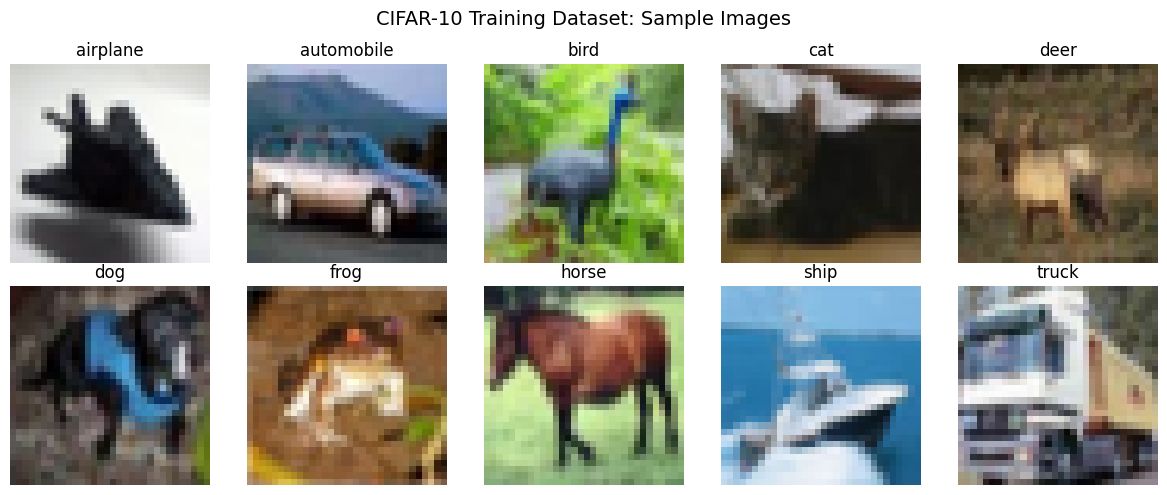

In [3]:
# Displaying one sample image from each class

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):

    # Finding the first image belonging to this class
    image_index = train_dataset.targets.index(class_id)

    image = train_dataset.data[image_index]

    ax.imshow(image)
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.suptitle("CIFAR-10 Training Dataset: Sample Images",
             fontsize=14)

plt.tight_layout()
plt.show()

#####**Interpretation of the CIFAR-10 Dataset**

CIFAR-10 contains 50,000 training images across ten classes, with 5,000 images per class. Each image is 32 x 32 pixels with three RGB channels. The dataset is balanced, but classification is challenging due to variations in object appearance, colour, position, and background. These characteristics make CIFAR-10 suitable for evaluating the model's ability to learn visual patterns and generalise to unseen images

### 3. Preprocessing and train/validation split


In [4]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import random_split, DataLoader

# Setting a reproducible random seed
SEED = 42
torch.manual_seed(SEED)

# CIFAR-10 normalisation statistics (per-channel mean and standard deviation of the training images)
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Defining preprocessing transformations:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Reloading CIFAR-10 with preprocessing
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transform
)

# Splitting into training and validation datasets (45,000 / 5,000)
train_size = 45000
val_size = 5000

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

# Loading the original test dataset separately
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Displaying partition sizes
print("Dataset partitioning completed!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nPreprocessing configuration:")
print("Transformation: ToTensor + Normalize")
print("Random seed:", SEED)

Dataset partitioning completed!
Training samples: 45000
Validation samples: 5000
Test samples: 10000

Preprocessing configuration:
Transformation: ToTensor + Normalize
Random seed: 42


### 4. Verifying the partitions


In [5]:
# Verify that all partitions have the expected sizes

assert len(train_dataset) == 45000
assert len(val_dataset) == 5000
assert len(test_dataset) == 10000

# Check a sample image (after normalisation the values are roughly in [-2, 2])
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Image data type:", image.dtype)
print("Image label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())



Image tensor shape: torch.Size([3, 32, 32])
Image data type: torch.float32
Image label: 6
Minimum pixel value: -1.9894737005233765
Maximum pixel value: 1.562813639640808


### 5. Checking the class balance of the training and validation sets


In [6]:
from collections import Counter

# Retrieve labels using the original dataset indices
train_labels = [
    full_train_dataset.targets[i]
    for i in train_dataset.indices
]

val_labels = [
    full_train_dataset.targets[i]
    for i in val_dataset.indices
]

print("Training and validation class distribution")


for i, name in enumerate(class_names):
    print(
        f"{name:12} | "
        f"Train: {train_labels.count(i):5} | "
        f"Validation: {val_labels.count(i):4}"
    )

Training and validation class distribution
airplane     | Train:  4512 | Validation:  488
automobile   | Train:  4488 | Validation:  512
bird         | Train:  4468 | Validation:  532
cat          | Train:  4529 | Validation:  471
deer         | Train:  4529 | Validation:  471
dog          | Train:  4486 | Validation:  514
frog         | Train:  4493 | Validation:  507
horse        | Train:  4500 | Validation:  500
ship         | Train:  4496 | Validation:  504
truck        | Train:  4499 | Validation:  501


### 6. Creating DataLoaders


In [7]:
from torch.utils.data import DataLoader

BATCH_SIZE = 128

# Training loader (shuffled every epoch so the model does not see the images in a fixed order.)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED)
)

# Validation and test loaders
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 352
Validation batches: 40
Test batches: 79


### 7. MLP model


In [8]:
import torch
import torch.nn as nn

class MLP(nn.Module):

    def __init__(self):
        super(MLP, self).__init__()

        # Flatten the 3D image into a 1D vector
        self.flatten = nn.Flatten()

        # First trainable layer: 3072 - 512
        self.fc1 = nn.Linear(3072, 512)

        # Second trainable layer: 512 - 256
        self.fc2 = nn.Linear(512, 256)

        # Third trainable layer: 256 - 10 (one raw score, or logit, per class)
        self.fc3 = nn.Linear(256, 10)

        # Activation function (ReLU = max(0, x))
        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.flatten(x)

        x = self.relu(self.fc1(x))

        x = self.relu(self.fc2(x))

        x = self.fc3(x)

        return x


# Initialising the model
model = MLP().to(device)

print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


#####**Interpretation of the MLP Architecture**

The MLP consists of three trainable fully connected layers with 512, 256, and 10 neurons. The input images are flattened into 3,072 features, and ReLU activation functions are used in the hidden layers to learn nonlinear patterns. The output layer produces ten class scores.

### 8. Calculating the trainable parameters


In [9]:

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("MLP Parameter Analysis")

# Parameters per tensor: a weight matrix (inputs x outputs) and a bias vector for each layer
for name, parameter in model.named_parameters():
    print(f"{name}: {parameter.numel():,} parameters")


print(f"Total trainable parameters: {total_params:,}")

MLP Parameter Analysis
fc1.weight: 1,572,864 parameters
fc1.bias: 512 parameters
fc2.weight: 131,072 parameters
fc2.bias: 256 parameters
fc3.weight: 2,560 parameters
fc3.bias: 10 parameters
Total trainable parameters: 1,707,274


#####**Interpretation of Trainable Parameters**

The MLP contains 1,707,274 trainable parameters, with approximately 92.2% located in the first fully connected layer. This large parameter count provides learning capacity but also increases model complexity and the risk of overfitting, especially when learning from a relatively small image dataset.

### 9. Verifying the model output


In [10]:

# Getting one batch of training images
images, labels = next(iter(train_loader))

# Moving images to GPU
images = images.to(device)

# Setting model to evaluation mode
model.eval()

# Perform a test forward pass
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Expected output shape: [128, 10]")

assert outputs.shape == (128, 10)


Input shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])
Expected output shape: [128, 10]


### 10. Defining the loss function, optimiser and training settings
- **Loss:** cross-entropy
- **Optimiser:** Adam, learning rate 0.001
- **Epochs:** 30
- **Batch size:** 128

In [11]:
# Defining the loss function
criterion = nn.CrossEntropyLoss()

# Training configuration
EPOCHS = 30
LEARNING_RATE = 0.001


print("Training configuration")
print("Loss function:", criterion)
print("Optimiser: Adam")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Training configuration
Loss function: CrossEntropyLoss()
Optimiser: Adam
Learning rate: 0.001
Batch size: 128
Epochs: 30


#####**Interpretation of Training Configuration**

The Adam optimiser with a learning rate of 0.001 and Cross-Entropy Loss was used for classification. A batch size of 128 and 30 training epochs were selected to train the model efficiently. Training was performed using the Tesla T4 GPU to accelerate computation.

### 11. Training and validation functions


In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clearing previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculating loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Updating model weights using those gradients
        optimizer.step()

        # Accumulating results
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

### 12. Training the MLP


In [13]:
import copy
import time


torch.manual_seed(SEED)
model = MLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Storing training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}


best_val_acc = 0.0
best_epoch = 0
best_state = None

start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # Store results
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)


    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    # results
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

training_time = time.time() - start_time
print(f"\nTraining finished in {training_time:.0f}s")
print(f"Best validation accuracy: {best_val_acc:.2f}% at epoch {best_epoch}")

Epoch [01/30] | Train Loss: 1.6588 | Train Acc: 41.18% | Val Loss: 1.5517 | Val Acc: 46.56%
Epoch [02/30] | Train Loss: 1.4402 | Train Acc: 49.31% | Val Loss: 1.4425 | Val Acc: 49.02%
Epoch [03/30] | Train Loss: 1.3285 | Train Acc: 53.26% | Val Loss: 1.4266 | Val Acc: 50.34%
Epoch [04/30] | Train Loss: 1.2424 | Train Acc: 56.11% | Val Loss: 1.4280 | Val Acc: 51.00%
Epoch [05/30] | Train Loss: 1.1595 | Train Acc: 58.92% | Val Loss: 1.3952 | Val Acc: 52.32%
Epoch [06/30] | Train Loss: 1.0834 | Train Acc: 61.65% | Val Loss: 1.4115 | Val Acc: 51.82%
Epoch [07/30] | Train Loss: 1.0124 | Train Acc: 63.86% | Val Loss: 1.4288 | Val Acc: 52.08%
Epoch [08/30] | Train Loss: 0.9387 | Train Acc: 66.62% | Val Loss: 1.5273 | Val Acc: 51.30%
Epoch [09/30] | Train Loss: 0.8691 | Train Acc: 69.16% | Val Loss: 1.5583 | Val Acc: 51.30%
Epoch [10/30] | Train Loss: 0.8045 | Train Acc: 71.26% | Val Loss: 1.6257 | Val Acc: 53.06%
Epoch [11/30] | Train Loss: 0.7389 | Train Acc: 73.78% | Val Loss: 1.6227 | Val 

### 13. Final results (training / validation / test)


In [14]:
model.load_state_dict(best_state)

final_train_loss, final_train_acc = evaluate(model, train_loader, criterion, device)
final_val_loss, final_val_acc = evaluate(model, val_loader, criterion, device)
final_test_loss, final_test_acc = evaluate(model, test_loader, criterion, device)

print("Final MLP performance (best-validation weights)")

print(f"Best epoch:          {best_epoch}")
print(f"Training   loss {final_train_loss:.4f} | accuracy {final_train_acc:.2f}%")
print(f"Validation loss {final_val_loss:.4f} | accuracy {final_val_acc:.2f}%")
print(f"Test       loss {final_test_loss:.4f} | accuracy {final_test_acc:.2f}%")
print(f"Train-test accuracy gap: {final_train_acc - final_test_acc:.2f} percentage points")


import pandas as pd

results = {
    "params": total_params,
    "best_epoch": best_epoch,
    "train_loss": final_train_loss,
    "train_acc": final_train_acc / 100,
    "val_loss": final_val_loss,
    "val_acc": final_val_acc / 100,
    "test_loss": final_test_loss,
    "test_acc": final_test_acc / 100,
    "gap": (final_train_acc - final_test_acc) / 100,
    "final_epoch_train_loss": history["train_loss"][-1],
    "time_s": training_time,
}
pd.DataFrame([results], index=["MLP"]).round(4).to_csv("ex1_results.csv")
print("\nSaved results to ex1_results.csv")

Final MLP performance (best-validation weights)
Best epoch:          10
Training   loss 0.7041 | accuracy 75.27%
Validation loss 1.6257 | accuracy 53.06%
Test       loss 1.6285 | accuracy 52.42%
Train-test accuracy gap: 22.85 percentage points

Saved results to ex1_results.csv


#####**Interpretation of Final MPL Performance**

The selected MLP model (epoch 10) achieved 75.27% training accuracy, 53.06% validation accuracy, and 52.42% test accuracy. The test result is considerably above the 10% random-guessing baseline for ten classes.

The 22.85 percentage-point difference between training and test accuracy indicates significant overfitting. However, the small difference between validation and test accuracy (0.64 percentage points) suggests that the validation performance provides a reasonable estimate of generalisation.

Overall, the MLP successfully learns image patterns but struggles to generalise to unseen images, highlighting the limitations of fully connected networks for image classification.

### 14. Training and validation loss


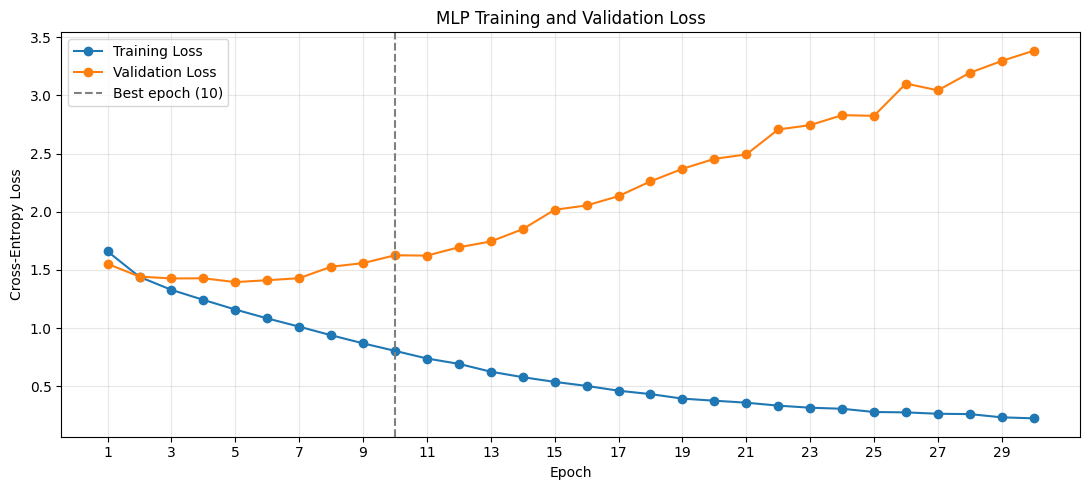

In [15]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(11, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(best_epoch, linestyle="--", color="grey", label=f"Best epoch ({best_epoch})")

plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, EPOCHS + 1, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_loss_curve.png", dpi=300)
plt.show()

#####**Interpretation of Training and Validation Loss**

The training loss decreased consistently from 1.6588 in the first epoch to
0.2248 in the final epoch, indicating that the model progressively learned patterns from the training data. However, the validation loss reached its minimum value of 1.3952 at epoch 5 and subsequently increased, reaching 3.3830 by epoch 30.

This divergence between training and validation loss indicates **overfitting**. The model continues improving its performance on training data but becomes less effective at generalising to unseen validation data. This suggests that the model is learning training specific patterns rather than sufficiently general features.

The results highlight that longer training does not necessarily improve model performance. Therefore, selecting the best model checkpoint based on validation performance is essential to reduce the impact of overfitting and improve generalisation.

### 15. Training and validation accuracy

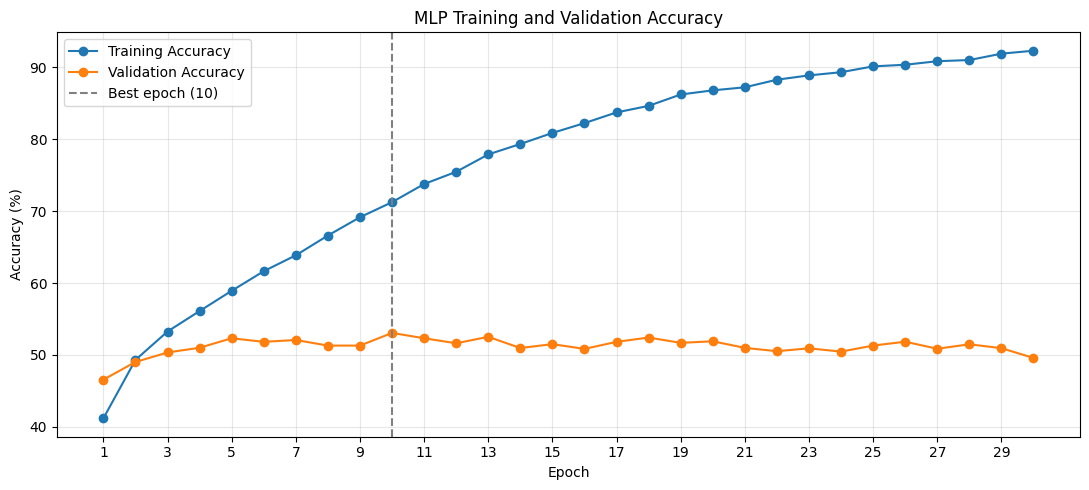

In [16]:
plt.figure(figsize=(11, 5))

plt.plot(
    epochs_range,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.axvline(best_epoch, linestyle="--", color="grey", label=f"Best epoch ({best_epoch})")

plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, EPOCHS + 1, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_accuracy_curve.png", dpi=300)
plt.show()

#####**Interpretation of Training and Validation Accuracy**

The training accuracy increased from 41.18% to 92.33%, showing that the model learned the training data effectively. However, validation accuracy remained around 50-53%, reaching its highest value of 53.06% at epoch 10.

The widening gap between training and validation accuracy indicates overfitting, as the model performs well on training data but struggles to generalise to unseen images. Therefore, epoch 10 was selected as the best model checkpoint based on validation accuracy.

### 16. Test confusion matrix and per-class accuracy


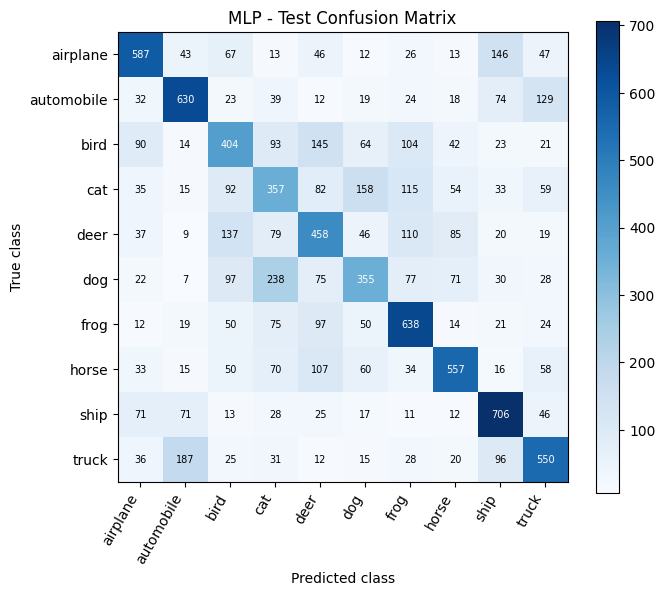

dog           35.5%
cat           35.7%
bird          40.4%
deer          45.8%
truck         55.0%
horse         55.7%
airplane      58.7%
automobile    63.0%
frog          63.8%
ship          70.6%


In [17]:
import numpy as np

model.eval()
conf_matrix = np.zeros((10, 10), dtype=int)

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(device)).argmax(1).cpu().numpy()
        for true_label, predicted_label in zip(labels.numpy(), predictions):
            conf_matrix[true_label, predicted_label] += 1

plt.figure(figsize=(7, 6))
plt.imshow(conf_matrix, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=60, ha="right")
plt.yticks(range(10), class_names)


for row in range(10):
    for col in range(10):
        plt.text(col, row, conf_matrix[row, col], ha="center", va="center", fontsize=7,
                 color="white" if conf_matrix[row, col] > conf_matrix.max() / 2 else "black")

plt.title("MLP - Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.savefig("mlp_confusion_matrix.png", dpi=300)
plt.show()


per_class_acc = conf_matrix.diagonal() / conf_matrix.sum(axis=1)
for index in np.argsort(per_class_acc):
    print(f"{class_names[index]:12} {100 * per_class_acc[index]:5.1f}%")

#####**Interpretation of Confusion Matrix and Per-Class Accuracy**

The model performs differently across the ten classes. Ship achieved the highest accuracy (70.6%), while dog (35.5%) and cat (35.7%) achieved the lowest. This indicates that the MLP struggles to distinguish certain animal categories. The results highlight the importance of class-wise evaluation rather than relying only on overall accuracy.

### 17. Saving the model and history


In [21]:

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "history": history,
        "best_epoch": best_epoch,
        "results": results,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
        "parameter_count": total_params
    },
    "mlp_baseline.pth"
)
print("Saved mlp_baseline.pth")

Saved mlp_baseline.pth


####**Overall Conclusion**

A Multi-Layer Perceptron (MLP) was implemented using PyTorch to classify CIFAR-10 images into ten categories. The model was trained using Adam optimiser and Cross-Entropy Loss.

The selected model achieved 52.42% test accuracy. However, the training and validation results revealed significant overfitting, while class-wise performance varied considerably.

Overall, the experiment demonstrates the limitations of fully connected networks in image classification, particularly their inability to effectively capture spatial features. The MLP also provides a useful baseline for comparison with the CNN model in the subsequent exercise.